# Лабораторная работа: Clustering — кластеризация данных

**Цель:** найти естественные группы похожих объектов недвижимости тремя методами — **K-Means**, **Agglomerative Clustering** и **DBSCAN** — сравнить их и объяснить, чем группы различаются.

**Важно:** кластеризация — *обучение без учителя*. Цена `SalePrice` **не используется** при построении кластеров. Её мы подключаем только после, чтобы проверить, соответствуют ли найденные группы ценовым сегментам.

**Файл данных:** `real_estate_regression_dataset.csv`. Исходный файл не изменяется: вся работа идёт с копией в памяти.

## Глава 1. Загрузка и первичный анализ данных (EDA)
Импортируем библиотеки, загружаем файл и смотрим структуру: размер, типы, пропуски, дубликаты, статистики.

 `!pip install pandas numpy matplotlib seaborn scikit-learn scipy`

In [1]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # убирает ложные предупреждения macOS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [2]:
# Загрузка исходных данных (df_raw остаётся нетронутым)
df_raw = pd.read_csv("../data/real_estate_regression_dataset.csv")
print("Строк:", df_raw.shape[0], "| Столбцов:", df_raw.shape[1])
df_raw.head()

Строк: 2840 | Столбцов: 28


,Id,Neighborhood,PropertyType,OverallQual,Condition,RenovationQuality,GrLivArea,LotArea,TotalBsmtSF,Rooms,Bedrooms,Bathrooms,Floor,TotalFloors,YearBuilt,YearRenovated,PropertyAge,GarageType,GarageCars,GarageArea,HeatingType,EnergyEfficiency,DistanceToCenter,HasPool,HasBalcony,CrimeRate,SchoolRating,SalePrice
0,994,GreenPark,Townhouse,9,Average,High,121,154.0,104.0,5,4,2,1,2,2016,2024.0,8,Detached,1,22.0,Electric,98.0,4.8,0,0,4.8,9.1,641900
1,279,Eastgate,House,9,Fair,Medium,90,1227.0,50.0,4,3,3,1,2,1982,2018.0,42,Attached,1,17.0,Gas,97.0,7.7,0,0,3.5,5.4,283500
2,820,OldTown,Apartment,4,Good,Low,104,0.0,0.0,3,2,1,1,5,1992,2024.0,32,NoGarage,0,0.0,Gas,97.0,2.5,0,0,4.6,5.9,365300
3,2700,Eastgate,Apartment,5,Good,Low,80,0.0,0.0,4,1,2,6,10,2012,2024.0,12,Underground,1,30.0,District,100.0,8.4,0,1,5.2,9.5,341200
4,1205,Downtown,House,9,Excellent,Medium,156,583.0,135.0,7,5,3,1,1,2018,2024.0,6,Detached,2,49.0,Electric,100.0,0.3,1,0,7.0,6.7,1238000


In [3]:
# Типы признаков, пропуски и дубликаты
info = pd.DataFrame({"тип": df_raw.dtypes, "пропусков": df_raw.isna().sum(),
                     "уникальных": df_raw.nunique()})
print(info.to_string())
print("\nПолных дубликатов:", df_raw.duplicated().sum())

                       тип  пропусков  уникальных
Id                   int64          0        2800
Neighborhood        object          0          13
PropertyType        object          0           6
OverallQual          int64          0          10
Condition           object        145           6
RenovationQuality   object        245           3
GrLivArea            int64          0         281
LotArea            float64        145         832
TotalBsmtSF        float64        249         205
Rooms                int64          0          10
Bedrooms             int64          0          11
Bathrooms            int64          0           7
Floor                int64          0          19
TotalFloors          int64          0          19
YearBuilt            int64          0          99
YearRenovated      float64        251          89
PropertyAge          int64          0          99
GarageType          object        182           6
GarageCars           int64          0           5


In [4]:
# Основные статистические характеристики числовых признаков
df_raw.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Id,2840.0,1401.3,808.2,1.0,701.8,1401.5,2101.2,2800.0
OverallQual,2840.0,6.1,1.6,1.0,5.0,6.0,7.0,10.0
GrLivArea,2840.0,128.9,59.0,29.0,84.0,120.0,159.0,538.0
LotArea,2695.0,338.0,556.1,0.0,0.0,221.0,463.5,11197.0
TotalBsmtSF,2591.0,55.4,56.5,0.0,0.0,53.0,92.0,449.0
Rooms,2840.0,5.4,1.8,2.0,4.0,5.0,6.0,11.0
Bedrooms,2840.0,3.4,1.6,1.0,2.0,3.0,4.0,12.0
Bathrooms,2840.0,2.2,1.0,1.0,1.0,2.0,3.0,7.0
Floor,2840.0,2.6,3.3,1.0,1.0,1.0,2.0,19.0
TotalFloors,2840.0,4.8,5.1,1.0,2.0,2.0,7.0,19.0


## Глава 2. Очистка и подготовка данных
1. **Дубликаты** удаляем: повторные строки искусственно «утяжеляют» одни и те же объекты и могут образовать ложные плотные группы.
2. **Пропуски** заполняем: числовые — медианой (устойчива к выбросам), категориальные — самым частым значением. Удалять строки с пропусками нельзя: потеряли бы около 40% данных, так как пропуски разбросаны по разным столбцам. В кластеризации (в отличие от обучения с учителем) нет тестовой выборки, поэтому утечки данных между train и test здесь не возникает.
3. **Выбросы** не удаляем: дорогие и очень большие объекты реальны. Ниже проверим, насколько они влияют на результат.

In [5]:
# Удаляем полные дубликаты, исходная таблица df_raw сохраняется
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Удалено дубликатов: {len(df_raw) - len(df)}. Осталось строк: {len(df)}")

# Заполнение пропусков: числа — медиана, категории — самое частое значение
num_all = df.select_dtypes(include="number").columns
cat_all = df.select_dtypes(exclude="number").columns
df[num_all] = df[num_all].fillna(df[num_all].median())
for c in cat_all:
    df[c] = df[c].fillna(df[c].mode()[0])
print("Пропусков после заполнения:", int(df.isna().sum().sum()))

# Сохраняем очищенный набор отдельно от исходного
df.to_csv("real_estate_clustering_clean.csv", index=False)

Удалено дубликатов: 40. Осталось строк: 2800
Пропусков после заполнения: 0


    признак  выбросов  доля, %
  GrLivArea        65      2.3
    LotArea       121      4.3
TotalBsmtSF        22      0.8
 GarageArea        12      0.4
   Bedrooms        51      1.8
  Bathrooms         4      0.1


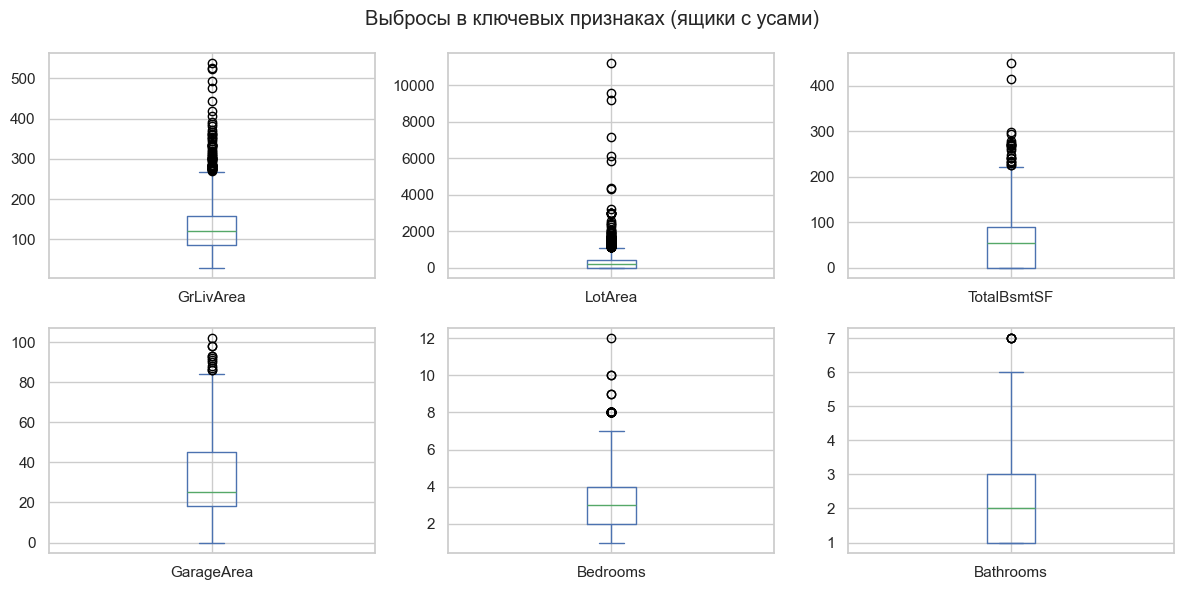

In [6]:
# Выбросы: сколько значений выходит за границы 1.5*IQR в ключевых признаках
key = ["GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea", "Bedrooms", "Bathrooms"]
rows = []
for c in key:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append({"признак": c, "выбросов": n_out, "доля, %": round(n_out / len(df) * 100, 1)})
print(pd.DataFrame(rows).to_string(index=False))

df[key].plot(kind="box", subplots=True, layout=(2, 3), figsize=(12, 6), sharex=False, sharey=False)
plt.suptitle("Выбросы в ключевых признаках (ящики с усами)")
plt.tight_layout()
plt.show()

## Глава 3. Выбор признаков и масштабирование

**Какие признаки используем и почему.**
- Берём числовые признаки, описывающие *сам объект и его окружение*: площади, спальни, ванные, качество, возраст, гараж, расстояние до центра, энергоэффективность, преступность, школы, бассейн, балкон.
- **Исключаем:** `Id` (просто номер), `SalePrice` (целевая переменная, обучение без учителя), `YearBuilt` (дублирует `PropertyAge`), `Rooms` и `GarageCars` (почти повторяют `Bedrooms` и `GarageArea`), `Floor` и `TotalFloors` (осмысленны только для квартир), `YearRenovated`.
- **Категориальные** (`Neighborhood`, `PropertyType`, `Condition` и др.) в алгоритмы **не передаём**: K-Means и DBSCAN считают евклидово расстояние, а one-hot признаки с 10+ категориями искажают его. Зато используем категории позже, чтобы *описать* получившиеся кластеры.

**Масштабирование.** Площади измеряются сотнями, а бинарные признаки — 0 и 1; без масштабирования площади «задавили» бы остальное. Из-за выбросов выбираем `RobustScaler` (опирается на медиану и IQR). Проверим, что выбор действительно важен.

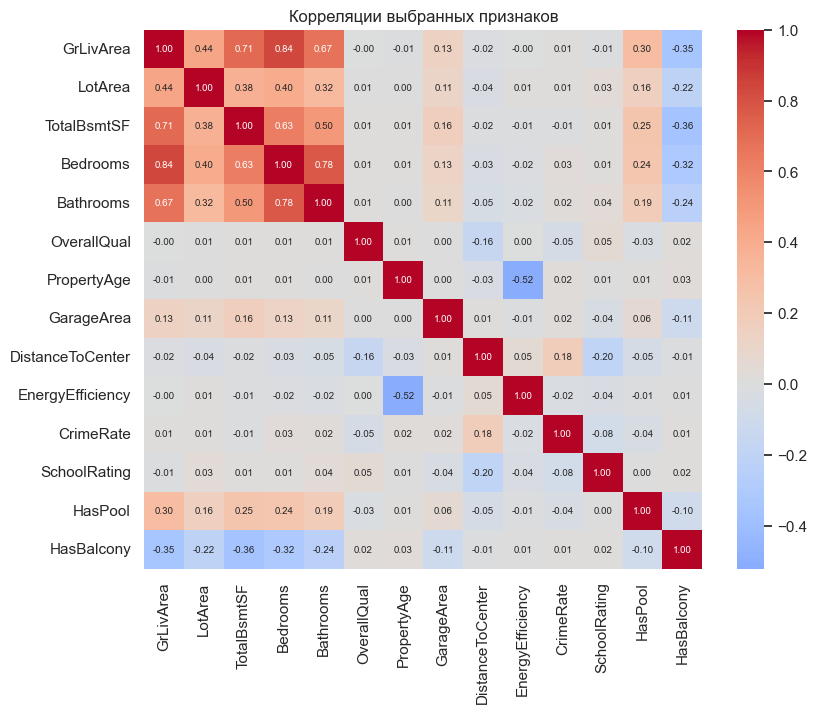

In [7]:
features = ["GrLivArea", "LotArea", "TotalBsmtSF", "Bedrooms", "Bathrooms", "OverallQual",
            "PropertyAge", "GarageArea", "DistanceToCenter", "EnergyEfficiency",
            "CrimeRate", "SchoolRating", "HasPool", "HasBalcony"]
X = df[features]

# Корреляции между выбранными признаками (проверка на дублирование информации)
plt.figure(figsize=(9, 7))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Корреляции выбранных признаков")
plt.show()

In [8]:
# Масштабирование двумя способами для сравнения
Z_std = StandardScaler().fit_transform(X)
Z = RobustScaler().fit_transform(X)       # основной вариант для дальнейшей работы

# Насколько выбросы влияют на результат: сравним разбиения K-Means на данных с разным масштабированием
# ARI = 1 — разбиения одинаковые, около 0 — совсем разные
for k in (3, 4, 5):
    a = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z_std)
    b = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    print(f"k={k}: ARI(StandardScaler vs RobustScaler) = {adjusted_rand_score(a, b):.3f}")

k=3: ARI(StandardScaler vs RobustScaler) = 0.448
k=4: ARI(StandardScaler vs RobustScaler) = 0.309
k=5: ARI(StandardScaler vs RobustScaler) = 0.384


**Как читать результат:** ARI заметно меньше 1 → на кластеры сильно влияют выбросы и способ масштабирования; значит, выбор `RobustScaler` обоснован. Он же важен как ограничение: результаты нестабильны к предобработке.

Доля дисперсии, объяснённая двумя компонентами: 0.416


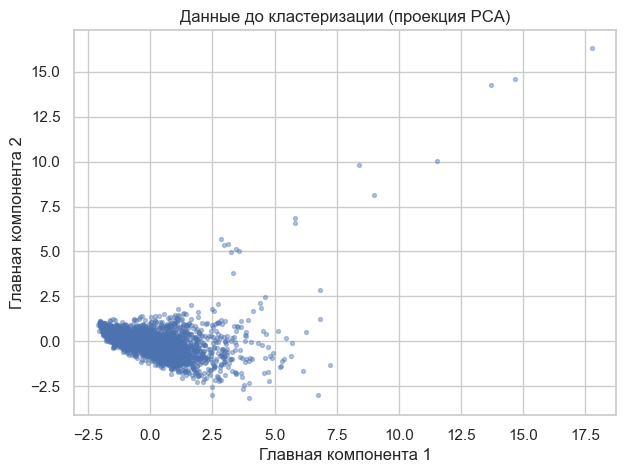

In [9]:
# 2D-проекция данных (PCA) — используем только для рисунков
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z2 = pca.fit_transform(Z)
print("Доля дисперсии, объяснённая двумя компонентами:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(7, 5))
plt.scatter(Z2[:, 0], Z2[:, 1], s=8, alpha=0.4)
plt.title("Данные до кластеризации (проекция PCA)")
plt.xlabel("Главная компонента 1")
plt.ylabel("Главная компонента 2")
plt.show()

Чёткого разделения на «острова» на картинке нет — группы, скорее всего, будут нечёткими. Это нормальная ситуация для реальных данных, и далее мы оцениваем её числами.

## Глава 4. K-Means
**Принцип работы простыми словами:** задаём число кластеров `k`; алгоритм ставит `k` «центров», относит каждый объект к ближайшему центру, пересчитывает центры как средние по группе и повторяет, пока центры не перестанут сдвигаться.

**Параметры:** `n_clusters=k` (выбираем ниже), `n_init=10` (10 запусков с разными стартовыми центрами, берётся лучший), `random_state=42`.

**Как выбрать k:** смотрим *метод локтя* (inertia — суммарный разброс внутри кластеров; ищем «излом») и *коэффициент силуэта* (от −1 до 1; чем выше, тем чётче группы).

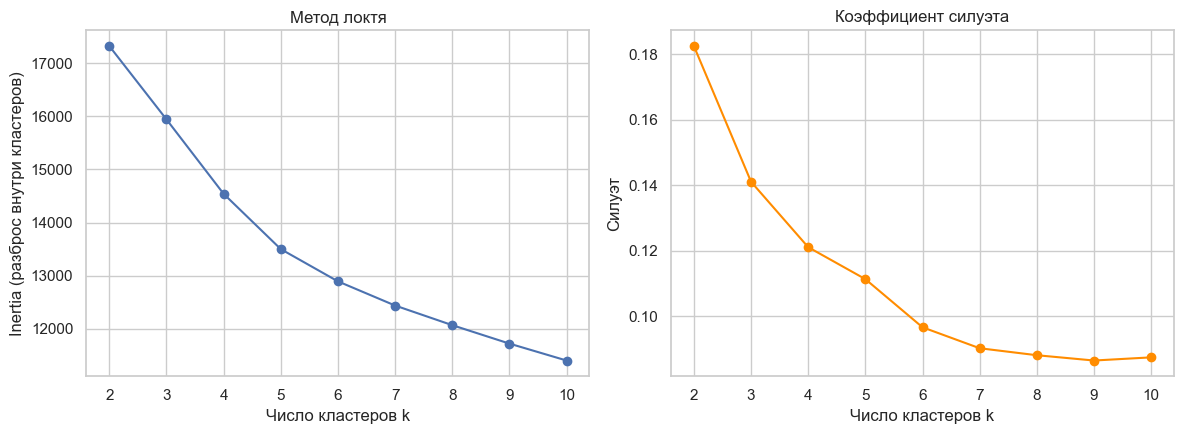

2     0.183
3     0.141
4     0.121
5     0.111
6     0.097
7     0.090
8     0.088
9     0.086
10    0.087


In [10]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(ks), inertia, "o-")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("Число кластеров k")
axes[0].set_ylabel("Inertia (разброс внутри кластеров)")
axes[1].plot(list(ks), sil, "o-", color="darkorange")
axes[1].set_title("Коэффициент силуэта")
axes[1].set_xlabel("Число кластеров k")
axes[1].set_ylabel("Силуэт")
plt.tight_layout()
plt.show()
print(pd.Series(sil, index=list(ks)).round(3).to_string())

**Выбор k.** Максимальный силуэт обычно у `k=2` — но это слишком грубое деление (по сути «большие и малые объекты»). Излом на кривой локтя выражен слабо; силуэт при `k=3–5` держится примерно на одном уровне. Для содержательной интерпретации берём **k = 4**. Это компромисс; его же можно менять в ячейке ниже и сравнивать.

In [11]:
K = 4

def relabel_by_size(labels, values):
    # Нумеруем кластеры по возрастанию средней жилой площади, чтобы номера были понятными и стабильными
    order = pd.Series(values).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[l] for l in labels])

km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)
labels_km = relabel_by_size(km.labels_, df["GrLivArea"].values)
df["KMeans"] = labels_km
print(df["KMeans"].value_counts().sort_index())

KMeans
0    1228
1     684
2      15
3     873
Name: count, dtype: int64


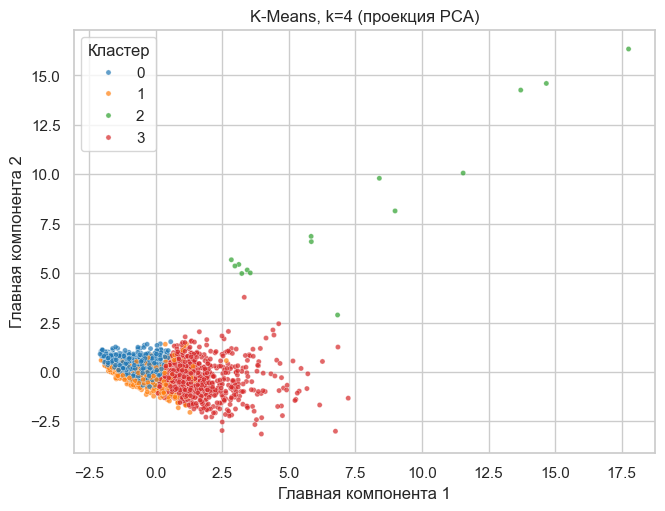

In [12]:
# Визуализация K-Means в проекции PCA
plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=labels_km, palette="tab10", s=14, alpha=0.7)
plt.title(f"K-Means, k={K} (проекция PCA)")
plt.xlabel("Главная компонента 1")
plt.ylabel("Главная компонента 2")
plt.legend(title="Кластер")
plt.show()

**Ограничения K-Means:** нужно заранее знать `k`; ищет выпуклые, примерно круглые группы одинакового размера; чувствителен к выбросам и масштабу (мы это проверили выше); использует только числовые признаки.

## Глава 5. Agglomerative Clustering (иерархическая)
**Принцип работы простыми словами:** сначала каждый объект — отдельный кластер; на каждом шаге два ближайших кластера склеиваются, пока не останется нужное число. Способ `ward` склеивает пары, которые меньше всего увеличивают разброс внутри кластеров. Результат можно показать деревом — **дендрограммой**.

**Параметры:** `n_clusters=4` (как у K-Means, для честного сравнения), `linkage="ward"`.

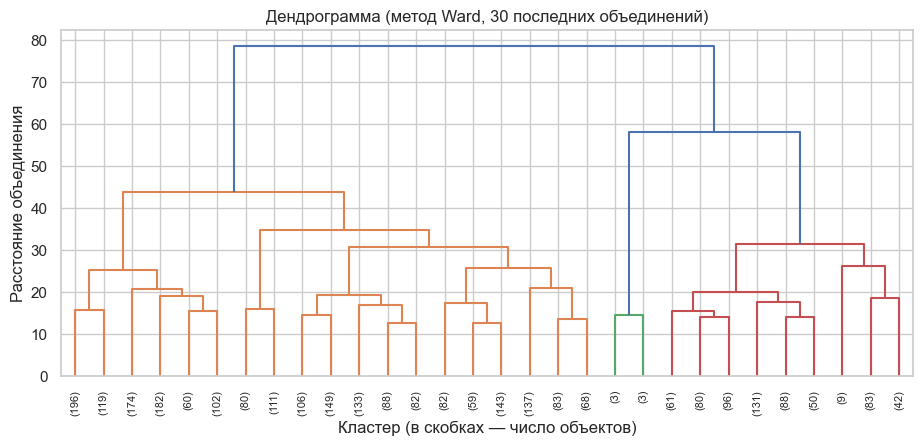

In [13]:
# Дендрограмма (показаны последние 30 объединений)
link = linkage(Z, method="ward")
plt.figure(figsize=(11, 4.5))
dendrogram(link, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8)
plt.title("Дендрограмма (метод Ward, 30 последних объединений)")
plt.xlabel("Кластер (в скобках — число объектов)")
plt.ylabel("Расстояние объединения")
plt.show()

Agglomerative
0     833
1    1321
2       6
3     640
Name: count, dtype: int64


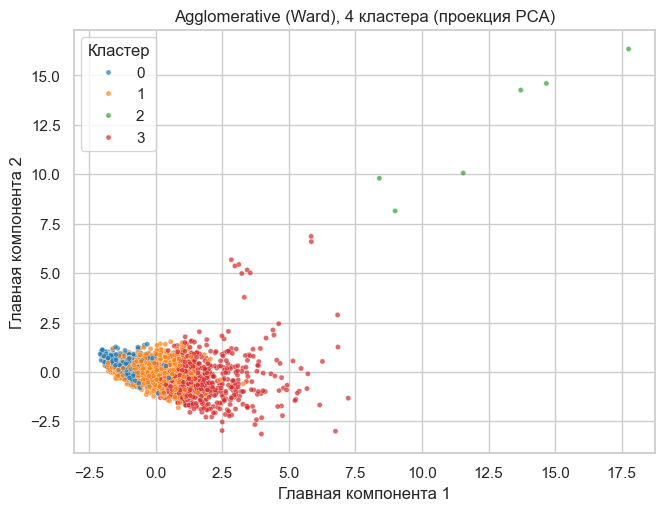

In [14]:
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
labels_agg = relabel_by_size(agg.labels_, df["GrLivArea"].values)
df["Agglomerative"] = labels_agg
print(df["Agglomerative"].value_counts().sort_index())

plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=labels_agg, palette="tab10", s=14, alpha=0.7)
plt.title(f"Agglomerative (Ward), {K} кластера (проекция PCA)")
plt.xlabel("Главная компонента 1")
plt.ylabel("Главная компонента 2")
plt.legend(title="Кластер")
plt.show()

**Ограничения:** алгоритм хранит попарные расстояния, поэтому медленный на больших выборках (для ~2800 объектов нормально, для сотен тысяч — нет); решение о слиянии нельзя отменить; `ward` тоже склонен к круглым кластерам и чувствителен к выбросам.

## Глава 6. DBSCAN (по плотности)
**Принцип работы простыми словами:** кластер — это область, где объекты расположены плотно. Объект с достаточным числом соседей в радиусе `eps` — «ядро» кластера; редкие объекты вдали от плотных областей помечаются как **шум** (метка `-1`). Число кластеров задавать не нужно.

**Параметры:** `eps` — радиус соседства, `min_samples` — сколько соседей нужно для «ядра». `eps` выбираем по графику *k-расстояний*: для каждого объекта берём расстояние до его k-го соседа, сортируем и ищем излом.

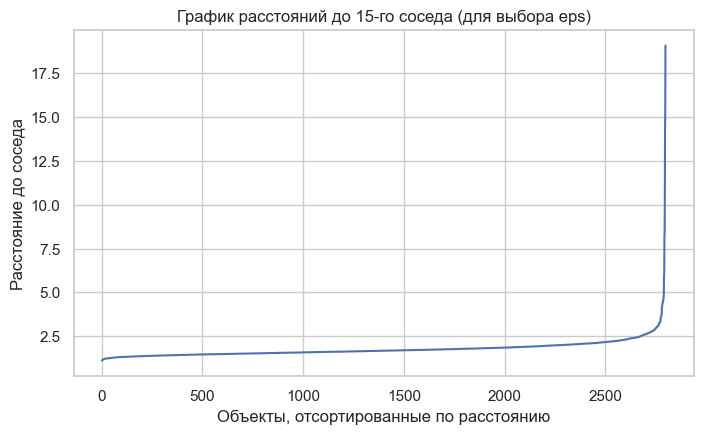

Перцентили расстояния (50/80/90/95/99%): [1.67 1.97 2.18 2.44 3.29]


In [15]:
MIN_SAMPLES = 15

# График k-расстояний для выбора eps
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z)
dist, _ = nn.kneighbors(Z)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(kdist)
plt.title(f"График расстояний до {MIN_SAMPLES}-го соседа (для выбора eps)")
plt.xlabel("Объекты, отсортированные по расстоянию")
plt.ylabel("Расстояние до соседа")
plt.show()
print("Перцентили расстояния (50/80/90/95/99%):", np.percentile(kdist, [50, 80, 90, 95, 99]).round(2))

In [16]:
# Перебор eps: как меняется число кластеров и доля шума
rows = []
for eps in np.round(np.percentile(kdist, [60, 70, 80, 90, 95]), 2):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Z)
    n_cl = len(set(lab) - {-1})
    rows.append({"eps": eps, "кластеров": n_cl, "шум, %": round((lab == -1).mean() * 100, 1),
                 "в крупнейшем кластере, %": round(pd.Series(lab[lab != -1]).value_counts(normalize=True).max() * 100, 1) if n_cl else 0})
pd.DataFrame(rows)

,eps,кластеров,"шум, %","в крупнейшем кластере, %"
0,1.74,1,13.8,100.0
1,1.83,1,9.8,100.0
2,1.97,1,6.3,100.0
3,2.18,1,3.4,100.0
4,2.44,1,1.6,100.0


eps = 2.18, min_samples = 15
Распределение меток (-1 — шум):
-1      95
 0    2705
Name: count, dtype: int64


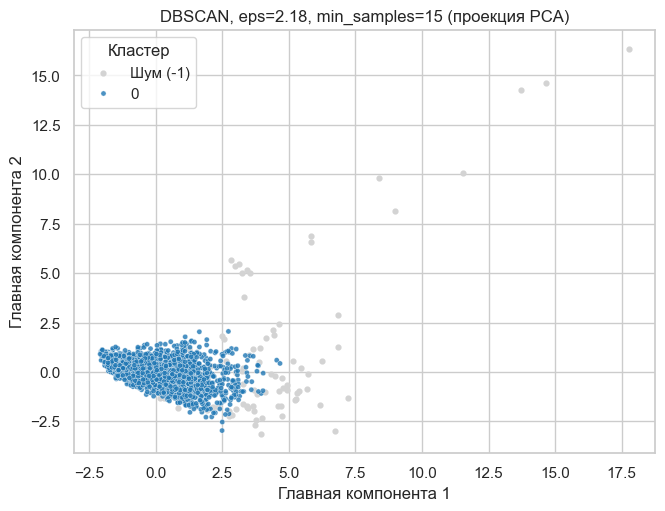

In [17]:
# Основной вариант: eps = 90-й перцентиль k-расстояний (правило: шумом считаем ~10% самых «одиноких» объектов)
EPS = float(np.percentile(kdist, 90))
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Z)
labels_db = db.labels_
df["DBSCAN"] = labels_db
print(f"eps = {EPS:.2f}, min_samples = {MIN_SAMPLES}")
print("Распределение меток (-1 — шум):")
print(pd.Series(labels_db).value_counts().sort_index())

plt.figure(figsize=(7.5, 5.5))
mask = labels_db == -1
plt.scatter(Z2[mask, 0], Z2[mask, 1], c="lightgray", s=12, label="Шум (-1)")
sns.scatterplot(x=Z2[~mask, 0], y=Z2[~mask, 1], hue=labels_db[~mask], palette="tab10", s=14, alpha=0.8)
plt.title(f"DBSCAN, eps={EPS:.2f}, min_samples={MIN_SAMPLES} (проекция PCA)")
plt.xlabel("Главная компонента 1")
plt.ylabel("Главная компонента 2")
plt.legend(title="Кластер")
plt.show()

**Как читать результат:** если почти все объекты попали в один кластер, а остальное — шум, значит, в данных нет явно разделённых по плотности групп: облако объектов непрерывное, и DBSCAN выделяет лишь «ядро» и «края». Это не ошибка кода, а свойство данных. **Ограничения DBSCAN:** трудно подобрать один `eps` для групп разной плотности, плохо работает в пространстве с большим числом признаков (расстояния становятся похожими), результат очень чувствителен к `eps`.

## Глава 7. Сравнение методов
Внутренние метрики качества (без использования цены):
- **Silhouette** — выше лучше (макс. 1);
- **Davies–Bouldin** — ниже лучше;
- **Calinski–Harabasz** — выше лучше.

Для DBSCAN метрики считаются без шума и только если найдено ≥ 2 кластеров.

In [18]:
def metrics(Zm, lab):
    m = lab != -1
    if len(set(lab[m])) < 2:
        return [np.nan, np.nan, np.nan]
    return [silhouette_score(Zm[m], lab[m]), davies_bouldin_score(Zm[m], lab[m]),
            calinski_harabasz_score(Zm[m], lab[m])]

comp = pd.DataFrame(
    {"K-Means": metrics(Z, labels_km), "Agglomerative": metrics(Z, labels_agg), "DBSCAN": metrics(Z, labels_db)},
    index=["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]).T.round(3)
comp["кластеров"] = [len(set(labels_km)), len(set(labels_agg)), len(set(labels_db) - {-1})]
comp["шум, %"] = [0, 0, round((labels_db == -1).mean() * 100, 1)]
comp

,Silhouette,Davies-Bouldin,Calinski-Harabasz,кластеров,"шум, %"
K-Means,0.121,1.889,415.182,4,0.0
Agglomerative,0.065,2.248,349.840,4,0.0
DBSCAN,NaN,NaN,NaN,1,3.4


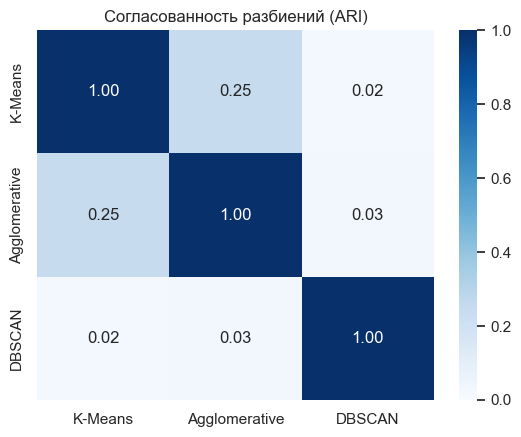

In [19]:
# Насколько методы согласуются друг с другом (ARI: 1 — одинаково, ~0 — совсем по-разному)
ari = pd.DataFrame(index=["K-Means", "Agglomerative", "DBSCAN"], columns=["K-Means", "Agglomerative", "DBSCAN"], dtype=float)
sets = {"K-Means": labels_km, "Agglomerative": labels_agg, "DBSCAN": labels_db}
for a in sets:
    for b in sets:
        ari.loc[a, b] = adjusted_rand_score(sets[a], sets[b])
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Согласованность разбиений (ARI)")
plt.show()

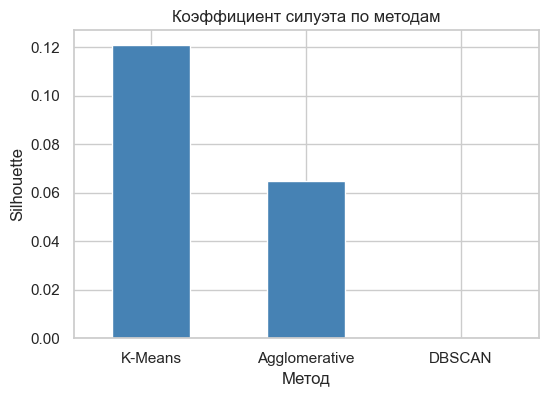

In [20]:
# Сравнение метрик графиком (для методов, у которых они определены)
comp[["Silhouette"]].plot(kind="bar", legend=False, figsize=(6, 4), rot=0, color="steelblue")
plt.title("Коэффициент силуэта по методам")
plt.xlabel("Метод")
plt.ylabel("Silhouette")
plt.show()

## Глава 8. Интерпретация кластеров K-Means
Теперь, когда кластеры построены, смотрим, чем они различаются: средние значения признаков, цена (`SalePrice`, использована **только здесь**) и категориальные признаки.

In [21]:
# Профиль кластеров: средние значения признаков по группам (в исходных единицах)
profile = df.groupby("KMeans")[features].mean().round(1)
profile.insert(0, "размер", df["KMeans"].value_counts().sort_index())
profile

,размер,GrLivArea,LotArea,TotalBsmtSF,Bedrooms,Bathrooms,OverallQual,PropertyAge,GarageArea,DistanceToCenter,EnergyEfficiency,CrimeRate,SchoolRating,HasPool,HasBalcony
KMeans,,,,,,,,,,,,,,,
0,1228,93.3,120.5,27.0,2.4,1.7,6.1,26.2,24.9,6.1,91.2,5.8,6.6,0.0,0.5
1,684,114.9,228.9,48.1,3.1,2.0,6.1,56.2,30.4,5.7,70.7,5.8,6.7,0.0,0.4
2,15,117.3,5266.3,52.9,3.3,2.1,5.9,29.8,32.3,4.5,88.7,6.1,7.5,0.1,0.3
3,873,190.8,632.1,101.3,5.1,3.2,6.1,31.7,33.2,6.0,88.4,5.9,6.7,0.1,0.2


        count    median      mean     min      max
KMeans                                            
0        1228  375000.0  399734.0   82500  1329900
1         684  382850.0  401739.0   99600  1335100
2          15  636300.0  667740.0  335700  1228900
3         873  600700.0  658456.0  199800  2951700


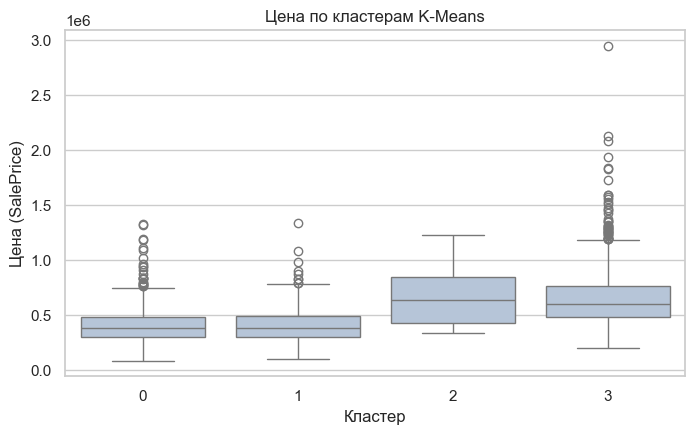

In [22]:
# Цена по кластерам — проверка постфактум (цена в кластеризации не участвовала)
print(df.groupby("KMeans")["SalePrice"].agg(["count", "median", "mean", "min", "max"]).round(0).to_string())

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x="KMeans", y="SalePrice", color="lightsteelblue")
plt.title("Цена по кластерам K-Means")
plt.xlabel("Кластер")
plt.ylabel("Цена (SalePrice)")
plt.show()

In [23]:
# Состав кластеров по типу недвижимости и состоянию (доли внутри кластера)
print("Тип недвижимости, % внутри кластера:")
print((pd.crosstab(df["KMeans"], df["PropertyType"], normalize="index") * 100).round(0).to_string())
print("\nТоп-3 района в каждом кластере, %:")
for c in sorted(df["KMeans"].unique()):
    print(c, (df.loc[df["KMeans"] == c, "Neighborhood"].value_counts(normalize=True).head(3) * 100).round(0).to_dict())

Тип недвижимости, % внутри кластера:
PropertyType  Apartment  Duplex  House  Penthouse  Townhouse  Villa
KMeans                                                             
0                  56.0     8.0   18.0        0.0       18.0    0.0
1                  31.0    12.0   36.0        0.0       21.0    0.0
2                  40.0     7.0   27.0        0.0       20.0    7.0
3                   0.0    12.0   66.0        0.0       12.0   10.0

Топ-3 района в каждом кластере, %:
0 {'Midtown': 13.0, 'Suburbia': 12.0, 'Westfield': 12.0}
1 {'Midtown': 17.0, 'Suburbia': 12.0, 'GreenPark': 10.0}
2 {'Midtown': 27.0, 'Eastgate': 27.0, 'Riverside': 13.0}
3 {'Midtown': 13.0, 'Suburbia': 12.0, 'GreenPark': 11.0}


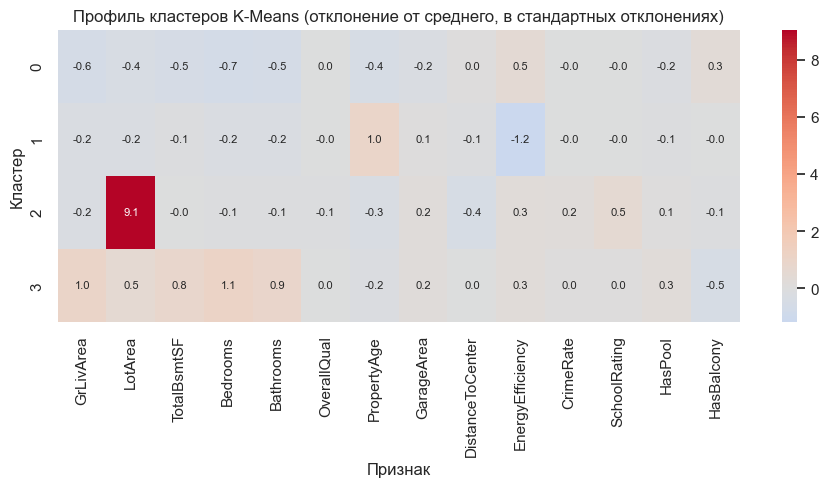

In [24]:
# Тепловая карта: насколько средний признак кластера выше/ниже общего среднего (в долях стандартного отклонения)
z = (df.groupby("KMeans")[features].mean() - df[features].mean()) / df[features].std()
plt.figure(figsize=(11, 3.8))
sns.heatmap(z, annot=True, fmt=".1f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Профиль кластеров K-Means (отклонение от среднего, в стандартных отклонениях)")
plt.xlabel("Признак")
plt.ylabel("Кластер")
plt.show()

**Как интерпретировать:** в таблице и на тепловой карте найдите для каждого кластера 2–3 признака с наибольшим отклонением (красные и синие клетки) — это и есть его «портрет». Затем сопоставьте с ценой и типом недвижимости и дайте кластеру название, например «компактные квартиры», «большие дома с участком» и т. д. (названия пишите по вашим результатам; ниже — автоматические подсказки).

In [25]:
# Автоматическая подсказка: два самых характерных признака каждого кластера
for c in z.index:
    top = z.loc[c].abs().sort_values(ascending=False).head(2).index
    desc = ", ".join(f"{f} ({'выше' if z.loc[c, f] > 0 else 'ниже'} среднего на {abs(z.loc[c, f]):.1f} ст.откл.)" for f in top)
    med = df.loc[df["KMeans"] == c, "SalePrice"].median()
    print(f"Кластер {c} ({(df['KMeans'] == c).sum()} объектов, медианная цена {med:,.0f}): {desc}")

Кластер 0 (1228 объектов, медианная цена 375,000): Bedrooms (ниже среднего на 0.7 ст.откл.), GrLivArea (ниже среднего на 0.6 ст.откл.)
Кластер 1 (684 объектов, медианная цена 382,850): EnergyEfficiency (ниже среднего на 1.2 ст.откл.), PropertyAge (выше среднего на 1.0 ст.откл.)
Кластер 2 (15 объектов, медианная цена 636,300): LotArea (выше среднего на 9.1 ст.откл.), SchoolRating (выше среднего на 0.5 ст.откл.)
Кластер 3 (873 объектов, медианная цена 600,700): Bedrooms (выше среднего на 1.1 ст.откл.), GrLivArea (выше среднего на 1.0 ст.откл.)


**Пример интерпретации по результатам запуска** (сверьте со своими цифрами; номера кластеров упорядочены по средней жилой площади):
- **Кластер 0** — небольшие объекты (меньше всего спален и площади, больше всего квартир), недорогие.
- **Кластер 1** — старые объекты (возраст около 56 лет) с низкой энергоэффективностью, по цене близки к кластеру 0: возраст и энергоэффективность выделяют группу, но не сильно меняют цену.
- **Кластер 2** — крошечная группа (15 объектов) с огромными участками (`LotArea` в среднем более 5000 при типичных сотнях). Это **выбросы**, которые K-Means выделил в отдельный кластер, то есть один из четырёх кластеров «потрачен» на выбросы. Этот факт нужно отметить как ограничение.
- **Кластер 3** — большие дома (больше всего спален, ванных и площади, 66% домов, квартир нет), медианная цена существенно выше.
- Цена в кластеризации не участвовала, но кластеры 0–1 и 2–3 различаются по цене: кластеризация по характеристикам объекта частично воспроизводит ценовые сегменты.

## Глава 9. Заключение
Текст ниже формируется автоматически по реальным результатам, полученным выше.

In [26]:
best_sil = comp["Silhouette"].idxmax()
print("Выполнено: загрузка и EDA, удаление дубликатов, заполнение пропусков, проверка выбросов, "
      "выбор признаков, масштабирование RobustScaler, кластеризация тремя методами, сравнение и интерпретация.")
print(f"Объектов после очистки: {len(df)}; признаков в кластеризации: {len(features)} (SalePrice не использовалась).")
print()
print("Метрики по методам:")
print(comp.to_string())
print()
print(f"Наибольший силуэт у метода «{best_sil}» ({comp.loc[best_sil, 'Silhouette']:.3f}). "
      f"Значения силуэта ниже ~0.25 означают, что кластеры выражены слабо и частично перекрываются.")
noise = comp.loc["DBSCAN", "шум, %"]
print(f"DBSCAN нашёл {int(comp.loc['DBSCAN', 'кластеров'])} кластер(а) и отнёс к шуму {noise}% объектов.")
med = df.groupby("KMeans")["SalePrice"].median()
print(f"Медианная цена по кластерам K-Means: {', '.join(f'{c}: {v:,.0f}' for c, v in med.items())}.")
print(f"Кластеры K-Means и Agglomerative согласуются на уровне ARI = {ari.loc['K-Means', 'Agglomerative']:.2f}.")

Выполнено: загрузка и EDA, удаление дубликатов, заполнение пропусков, проверка выбросов, выбор признаков, масштабирование RobustScaler, кластеризация тремя методами, сравнение и интерпретация.
Объектов после очистки: 2800; признаков в кластеризации: 14 (SalePrice не использовалась).

Метрики по методам:
               Silhouette  Davies-Bouldin  Calinski-Harabasz  кластеров  шум, %
K-Means             0.121           1.889            415.182          4     0.0
Agglomerative       0.065           2.248            349.840          4     0.0
DBSCAN                NaN             NaN                NaN          1     3.4

Наибольший силуэт у метода «K-Means» (0.121). Значения силуэта ниже ~0.25 означают, что кластеры выражены слабо и частично перекрываются.
DBSCAN нашёл 1 кластер(а) и отнёс к шуму 3.4% объектов.
Медианная цена по кластерам K-Means: 0: 375,000, 1: 382,850, 2: 636,300, 3: 600,700.
Кластеры K-Means и Agglomerative согласуются на уровне ARI = 0.25.


**Ограничения эксперимента:**
- данные синтетические, поэтому найденные «сегменты» отражают правила генерации датасета, а не реальный рынок;
- число кластеров `k=4` выбрано как компромисс: метрики не показывают чёткого оптимума;
- результаты зависят от предобработки (разные масштабирования дали разные разбиения), от выбора признаков и от параметров `eps` и `min_samples`;
- для оценки без разметки использовались только внутренние метрики, а они не доказывают «правильность» кластеров;
- проекция PCA на 2 компоненты показывает лишь часть структуры данных.
